In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split    #Dividir datos para test y train
from sklearn.linear_model import LogisticRegression     #Regresión logística
from sklearn.preprocessing import StandardScaler        #Estandarizar escalas numéricas
from sklearn.preprocessing import LabelEncoder          #Convertir categorias a numeros
from sklearn.metrics import(
    confusion_matrix,                                   #Matriz de confusión
    classification_report,                              #Metricas(precision, recall, F1)
    roc_auc_score,                                      #Area bajo la curva roc
    roc_curve,                                          #Puntos para graficar curva roc
    accuracy_score,                                     #métrica accuracy

)

import statsmodels.api as sm                            #Intervalos de confianza

import warnings
warnings.filterwarnings('ignore')


Importación de datos

In [3]:
pathFile = '../data/raw/Churn_Modelling.csv'
dataset = pd.read_csv(pathFile, encoding='utf-8')
dataset.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
#Se trabajará con una copia del dataset original
df_bank = dataset.copy()
print(f'Número de clientes:{df_bank.shape[0]:,}')
print(f'Número de variables:{df_bank.shape[1]}')
df_bank.tail()

Número de clientes:10,000
Número de variables:14


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


Revisión inicial del dataset

In [5]:
df_bank.info()
#No se obserban datos nulos
#El tipo de dato corresponde a cada variable 

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [6]:
Duplicated_Rows = df_bank[df_bank.duplicated(subset=['CustomerId'])]
print("Duplicated data:", Duplicated_Rows)
#No hay información duplicada

Duplicated data: Empty DataFrame
Columns: [RowNumber, CustomerId, Surname, CreditScore, Geography, Gender, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary, Exited]
Index: []


In [7]:
df_bank.describe()
# No se identifican valores negativos


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [8]:
print("Clientes con salario < 1000€:", len(df_bank[df_bank['EstimatedSalary'] < 10000]))


Clientes con salario < 1000€: 508


Se observa un dato inusual en el mínimo de "EstimatedSalary" de 11.58 Euros. Este es un dato inusual, pero dado a que no se tiene conocimiento de cual es el origen de los datos para determinar si es un error tipográfico, se dejará esta columna de datos intacta. Además, aún si se tiene los salarios mínimos de España, Alemania y Francia referenciados entre 1200-2400 euros tomar todos los valores por debajo de 10000Euros anuales e inputarlos por la mediana repesentaría aprox. el 5% de los datos del dataset, por esta razón no se realizaran inmputaciones en esta columna de datos

In [9]:
#Se verifica que no existan textos en blanco '' que lo tome como valores
df_bank = df_bank.replace(r'^\s*$', np.nan, regex= True)
Count_null = df_bank.isna().sum()
print(Count_null)

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [10]:
df_bank['Geography'].value_counts()
#No hay errores de ortografía y se encuentra unificado, se obserba mayor cantidad de clientes en Francia

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Número de clientes que abandonaron el banco:2037 (20.37%)
Número de clientes que permanecen en el banco: 7963 (79.63%)
Tasa de churn: 20.37%
Ratio de desblanceo: 3.91:1
Por cada 3.91 clientes que se quedan, 1 abandona el banco
      Ejemplo: En un caso de 391 clientes que se quedan, 100 abandonan el banco aportando a la tasa de Churn


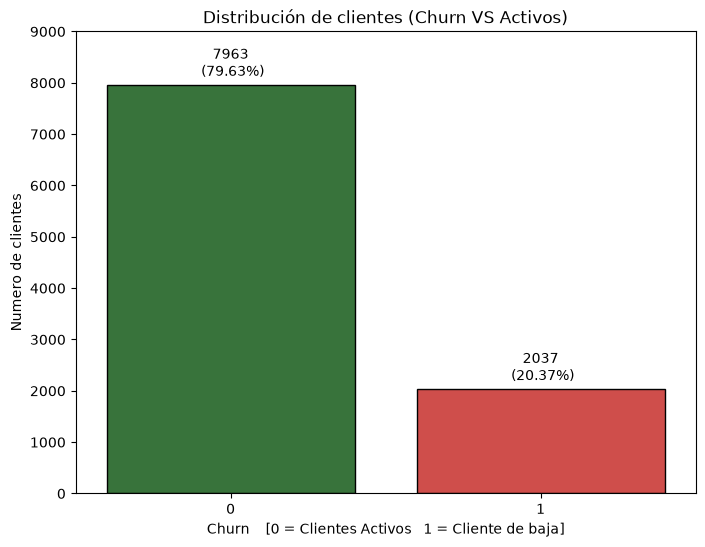

In [11]:
#Grafico de barras para la variable de interes 'Exited' para ver la distribución del 'churn'
churn_count = df_bank['Exited'].value_counts()
churn_percentages = df_bank['Exited'].value_counts(normalize=True)*100
print(f'Número de clientes que abandonaron el banco:{churn_count[1]} ({churn_percentages[1]:.2f}%)')
print(f'Número de clientes que permanecen en el banco: {churn_count[0]} ({churn_percentages[0]:.2f}%)')
print(f'Tasa de churn: {churn_percentages[1]:.2f}%')
print(f'Ratio de desblanceo: {churn_count[0]/churn_count[1]:.2f}:1')
print(f'''Por cada {churn_count[0]/churn_count[1]:.2f} clientes que se quedan, 1 abandona el banco
      Ejemplo: En un caso de 391 clientes que se quedan, 100 abandonan el banco aportando a la tasa de Churn''')

plt.figure(figsize=(8,6))
colors = ['#2E7D32', '#E53935']
ax = sns.countplot(x='Exited', data = df_bank, palette=colors, edgecolor='black')

plt.title('Distribución de clientes (Churn VS Activos)')
plt.xlabel('Churn    [0 = Clientes Activos   1 = Cliente de baja]')
plt.ylabel('Numero de clientes')
labels = [f'{churn_count[0]}\n ({churn_percentages[0]:.2f}%)',
          f'{churn_count[1]}\n ({churn_percentages[1]:.2f}%)']

ax.bar_label(ax.containers[0], labels=[labels[0]], padding=3)
ax.bar_label(ax.containers[1], labels=[labels[1]], padding=3)

plt.ylim(0, 9000)
plt.show()

Datos desbalanceados, se enfocará en recall y precisón, texto compreoto en las notas

In [12]:
#Impacto monetario en el banco
churn_loss = df_bank.loc[df_bank['Exited']== 1, 'Balance'].sum()
mean_churn_loss = df_bank.loc[df_bank['Exited']== 1, 'Balance'].mean()

print(f'Pérdida de capacidad de fondeo total anual: € {churn_loss:.2f}')
print(f'Pérdida de capacidad en promedio anual por cliente: € {mean_churn_loss:.2f}')

Pérdida de capacidad de fondeo total anual: € 185588094.63
Pérdida de capacidad en promedio anual por cliente: € 91108.54


In [13]:
df_cat = df_bank[['Geography', 'Gender',  'NumOfProducts', 'HasCrCard', 'IsActiveMember']]
df_cat.head()

,Geography,Gender,NumOfProducts,HasCrCard,IsActiveMember
0,France,Female,1,1,1
1,Spain,Female,1,0,1
2,France,Female,3,1,0
3,France,Female,2,0,0
4,Spain,Female,1,1,1


<function matplotlib.pyplot.show(close=None, block=None)>

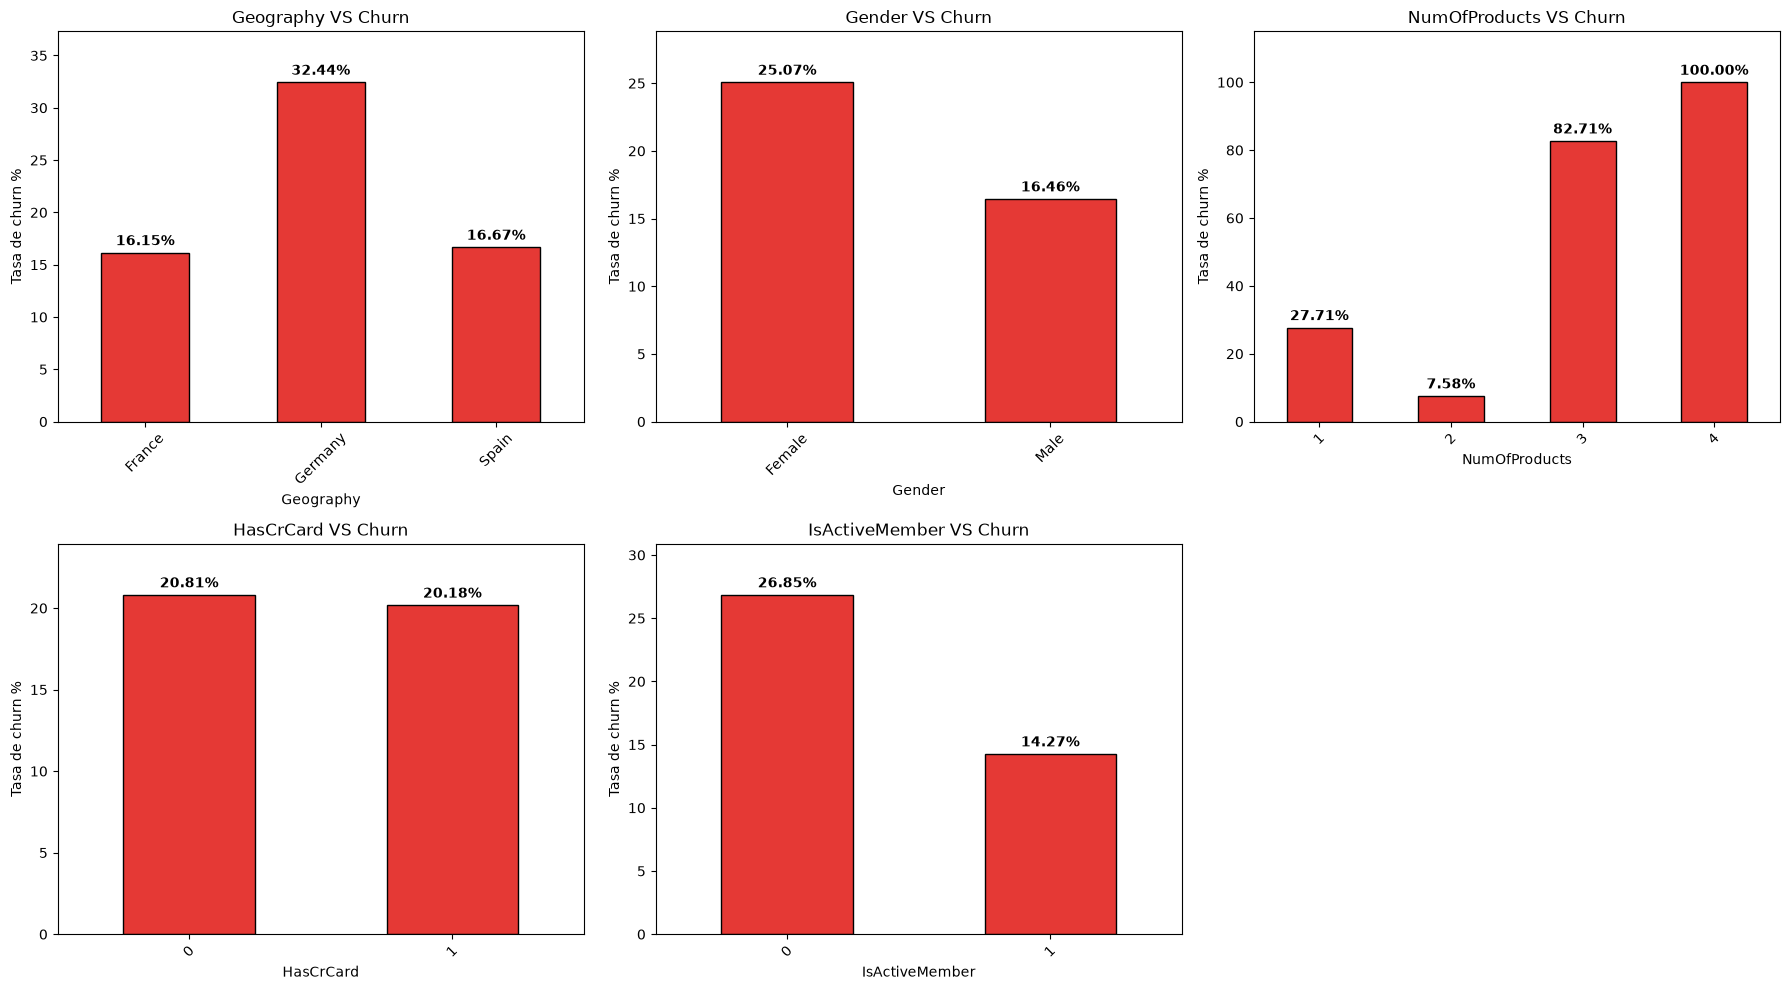

In [14]:
#Digramas de barras de las variables categóricas VS varible objetivo (Exited)
#Geography, Gender,  NumOfProducts, HasCrCard, IsActiveMember

categoricals = ['Geography', 'Gender',  'NumOfProducts', 'HasCrCard', 'IsActiveMember']
fig, axes = plt.subplots(2,3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(categoricals):
    df_tasa_churn = df_bank.groupby(col)['Exited'].mean() * 100

    df_tasa_churn.plot(kind='bar', ax=axes[i], color='#E53935', edgecolor='black')
   
    axes[i].bar_label(axes[i].containers[0], fmt='%.2f%%', padding=3, fontsize=10, fontweight='bold')
    axes[i].set_title(f'{col} VS Churn')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Tasa de churn %')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].margins(y=0.15)

if len(categoricals)<len(axes):
    axes[-1].set_visible(False)

plt.tight_layout() 
plt.show

Consideraciones e hipótesis
1. Alemania presenta la tasa más alta de abandono con un 32.44%, esto tecnicamente duplica a las tasas de abandono de Francia y España por separado
2. Hay un porcentaje de abandono del 25%. 8.6 puntos porcentuale mas alto que en de los hombres, esto se traduce que las mujeres tienen un 52.35% probabilidades más
de abandonar el banco 
3. Se observa una tendencia fuerte en el número de productos: Todos los clientes con 4 productos abandonaron el banco, seguidamente si tienen 3 productos 
la tasa es del 83%, dismuye para 1 producto en 27% y la más baja en 2 productos con un 7.6%
4. La proporción de abandono si tiene o no tiene tarjeta de crédito es casi idgual, por lo que se considera que no es determinante para la variable de estudio
5. Hay un mayor porcentaje de abandono, de un 26.9% si no es un miembro activo del banco

<function matplotlib.pyplot.show(close=None, block=None)>

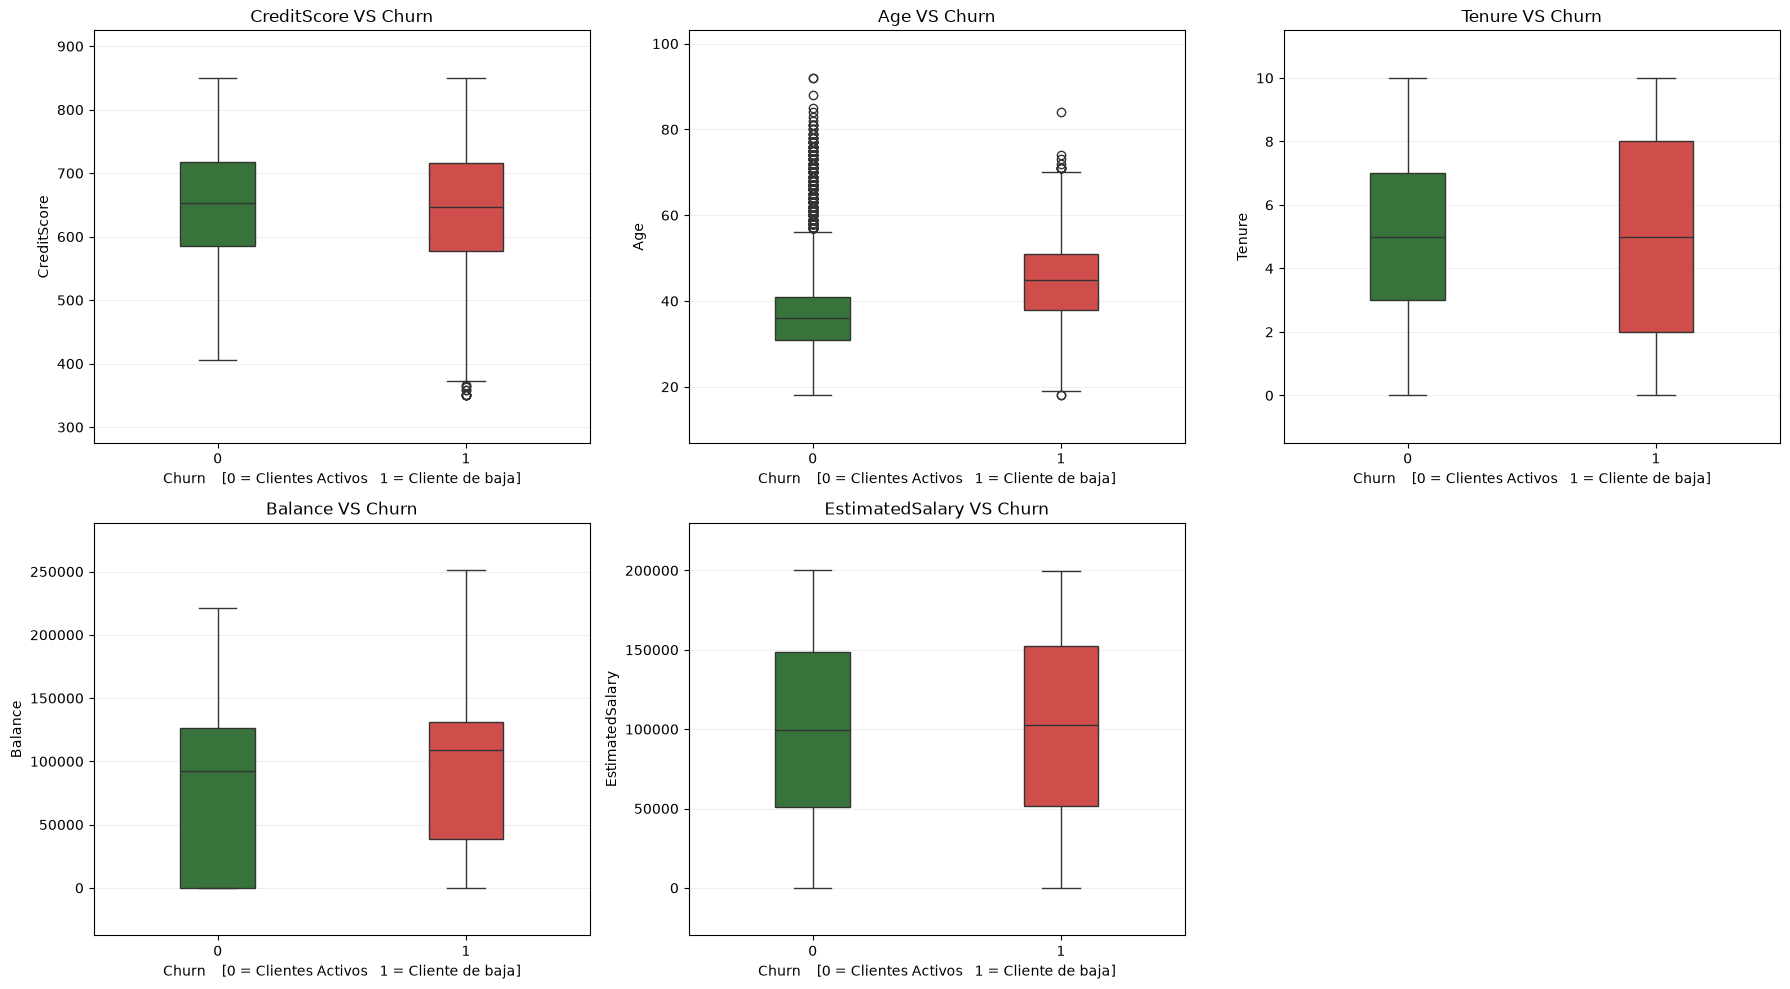

In [15]:
#Diagramas de cajas y bigotes VS varible objetivo (Exited)
#CreditScore, Age, Tenure, Balance, EstimatedSalary

Numericals = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2,3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(Numericals):

    sns.boxplot(data=df_bank, x='Exited', y=col, ax=axes[i], width=0.3, palette=['#2E7D32', '#E53935'])

    axes[i].set_title(f'{col} VS Churn')
    axes[i].set_xlabel('Churn    [0 = Clientes Activos   1 = Cliente de baja]')
    axes[i].set_ylabel(col)
    axes[i].margins(y=0.15)
    axes[i].grid(alpha=0.2, axis='y')

if len(categoricals)<len(axes):
    axes[-1].set_visible(False)

if len(categoricals)<len(axes):
    axes[-1].set_visible(False)

plt.tight_layout() 
plt.show

Consideraciones e hipótesis
1. Alemania presenta la tasa más alta de abandono con un 32.44%, esto tecnicamente duplica a las tasas de abandono de Francia y España por separado
2. Hay un porcentaje de abandono del 25%. 8.6 puntos porcentuale mas alto que en de los hombres, esto se traduce que las mujeres tienen un 52.35% probabilidades más
de abandonar el banco 
3. Se observa una tendencia fuerte en el número de productos: Todos los clientes con 4 productos abandonaron el banco, seguidamente si tienen 3 productos 
la tasa es del 83%, dismuye para 1 producto en 27% y la más baja en 2 productos con un 7.6%
4. La proporción de abandono si tiene o no tiene tarjeta de crédito es casi igual, por lo que se considera que no es determinante para la variable de estudio
5. Hay un mayor porcentaje de abandono, de un 26.9% si no es un miembro activo del banco
1. La mediana del creditScore para los clientes que se van y los que se quedan es de aprox. 650, por lo que se considera que no es determinante de churn
2. El 50% de las personas que se van tienen entre 39 y 50 años de edad con una mediana de 45 años, a diferencia de los que se quedan que el 75% de los datos están por debajo de los 42 años y muchos casos atípicos por encima de 58. Serían adultos mayores que se quedan en el banco
3.Tenure no parece indicar incidencia sobre el churn ya que la mediana está en 5 para ambos casos
4. El balance de los que se van tienen una mediana por encima de los 100,000 Euros y los que se quean por debajo. El banco está perdiendo clientes con mayor capital en la cuenta o con algún capital, mientras que hay clientes activos con balance de cuenta cero
5. El salario estimado no parece tener incidencia sobre el churn, la mediana de ambos están en 100,000 euros aproximadamente

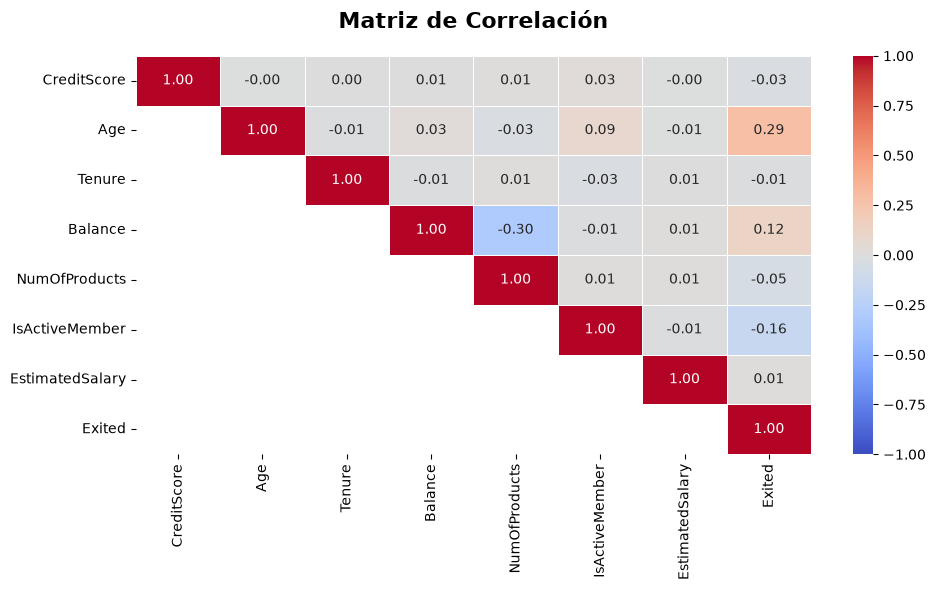

In [16]:
#matriz de correlación de variables
#Solo se tienen en cuentan las variable numéricas continuas o que se vea una escala/secuencia, como edad o balance. 
#No se tiene en cuenta variables categóricas como Geografía o género
#ya que la correlación de pearson pierde precisión porque las categorías no se comportan de forma continua

Corr_Var = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',  'IsActiveMember', 'EstimatedSalary', 'Exited']

Corr_matrix = df_bank[Corr_Var].corr()
#Máscara de filtrado sólo para el triángulo superior
mask= np.tril(np.ones_like(Corr_matrix, dtype=bool), k=-1)

plt.figure(figsize=(10,6))
sns.heatmap(Corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5,  vmin=-1, vmax=1, mask=mask)
plt.title('Matriz de Correlación', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

#|0.00| a |0.50| Sin problemas de colinealidad
#|0.50| a |0.70| Colinealidad moderada
#|0.70| a |1.00| Colinealidad alta

Consideraciones e hipótesis
1. Se observa algo de correlación positiva (0.29) entre la edad y Exited(churn) confirmando que a mayor edad más riesgo de abandono. 
2. Existe una leve correlación negativa entre el balance de saldo y el número de productos (NumOfProducts) a mayor balance, disminuye el num de productos de clientes y viceversa
3. Para la variable balance también se observa que a mayor balance aumentan las probabilidades de churn, como se evidenció en la gráfica de cajas y bigotes, representando una pérdida de capital valioso para el banco.
4. Si un cliente es un miembro activo hay menos probabilidades que se vaya, por lo que también tiene una leve correlación negativa con Exited

Preparación de datos para el modelo

In [17]:
# Antes de iniciar el análisis se eliminaran las columnas que no aporten al modelo
df_bank = df_bank.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df_bank.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Encoding de variable categóricas

In [18]:
le_gender = LabelEncoder()
df_bank['Gender'] = le_gender.fit_transform(df_bank['Gender'])
print(f'   Valores codificados: {df_bank['Gender'].unique()}')
print(f'   Mapeo: {dict(zip(le_gender.classes_, le_gender.transform(le_gender.classes_)))}')

#Para entornos de producción utilizar OneHotEncoder(handle_unknown='ignore') por si existen parámetros de prueba que no se tuvieron en cuenta en el modelo de entrenamiento
#con el fin de que no se rompa el modelo y tome el valor base, después se decide que acción tomar sobre estos nuevos datos
df_bank = pd.get_dummies(df_bank, columns=['Geography'], drop_first=True, dtype=int)
new_col = [col for col in df_bank.columns if col.startswith('Geography_')]
print(f'   Columnas creadas para Geography: {new_col}')

df_bank.head()

   Valores codificados: [0 1]
   Mapeo: {'Female': np.int64(0), 'Male': np.int64(1)}
   Columnas creadas para Geography: ['Geography_Germany', 'Geography_Spain']


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,1


Separación de features y target

In [19]:
x = df_bank.drop('Exited', axis = 1)
y = df_bank['Exited']

print(f'\nFeatures (X): {x.shape[1]} columnas')
print(f'Columnas: {list(x.columns)}')
print(f'\nTarget (y): {y.name}')
print(f'Distribución: \n{y.value_counts()}')


Features (X): 11 columnas
Columnas: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']

Target (y): Exited
Distribución: 
Exited
0    7963
1    2037
Name: count, dtype: int64


In [20]:
#Se dividen los datos en 80% para entenaminto y 20% para test, manteniento una proporción del 20.37% de churn para ambos grupos (stratify=y)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nConjunto de Entrenamiento:")
print(f"   X_train: {x_train.shape}")
print(f"   y_train: {y_train.shape}")
print(f"   Distribución de churn: \n{y_train.value_counts(normalize=True) * 100}")

print(f"\nConjunto de Prueba:")
print(f"   X_test: {x_test.shape}")
print(f"   y_test: {y_test.shape}")
print(f"   Distribución de churn: \n{y_test.value_counts(normalize=True) * 100}")


Conjunto de Entrenamiento:
   X_train: (8000, 11)
   y_train: (8000,)
   Distribución de churn: 
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64

Conjunto de Prueba:
   X_test: (2000, 11)
   y_test: (2000,)
   Distribución de churn: 
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [21]:
#Escalamiento de variables
scaler = StandardScaler()
#Escaneo de los datos de entrenamiento y cálulo de media y desviación
scaler.fit(x_train)

#transformación sólo con las métricas de entrenamiento
x_train_scaled= scaler.transform(x_train)
x_test_scaled= scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index= x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index= x_test.index)

print("\nDatos originales:")
print(x_train.iloc[:5, :4])
print("\nDatos escalados:")
print(x_train_scaled.iloc[:5, :4])


Datos originales:
      CreditScore  Gender  Age  Tenure
2151          753       1   57       7
8392          739       1   32       3
5006          755       0   37       0
4117          561       1   37       5
7182          692       1   49       6

Datos escalados:
      CreditScore    Gender       Age    Tenure
2151     1.058568  0.907507  1.715086  0.684723
8392     0.913626  0.907507 -0.659935 -0.696202
5006     1.079274 -1.101919 -0.184931 -1.731895
4117    -0.929207  0.907507 -0.184931 -0.005739
7182     0.427035  0.907507  0.955079  0.339492


Entrenamiento regresión logística

In [22]:
#Para el motor matemático se utiliza por defecto 'lbfgs'(compatible con la regularización L2 por defecto) para un dataset mediano como este. 
#Si fueran millones de registros se utilizaria sag o saga(o liblinear para regularización tipo L1) para big data
LR_model = LogisticRegression(random_state=42, max_iter=1000, solver='lbfgs')
LR_model.fit(x_train_scaled, y_train)

print(f"Solver: {LR_model.solver}")
print(f"Iteraciones: {LR_model.n_iter_[0]}")
print(f"Features: {len(LR_model.coef_[0])}")

Solver: lbfgs
Iteraciones: 6
Features: 11


In [23]:
#Coeficientes y odds ratio
coefficients = pd.DataFrame({
    'Variable': x_train.columns,
    'Coeficiente': LR_model.coef_[0],
    'Abs_Coeficiente': np.abs(LR_model.coef_[0])

}).sort_values('Abs_Coeficiente', ascending=False)
coefficients = coefficients.round(6)
print(f'Intercepto: {LR_model.intercept_[0]:.4f}')
display(coefficients)

Intercepto: -1.6459


,Variable,Coeficiente,Abs_Coeficiente
2,Age,0.738847,0.738847
7,IsActiveMember,-0.515485,0.515485
9,Geography_Germany,0.356679,0.356679
1,Gender,-0.260851,0.260851
4,Balance,0.160622,0.160622
0,CreditScore,-0.085986,0.085986
5,NumOfProducts,-0.070292,0.070292
8,EstimatedSalary,0.047725,0.047725
6,HasCrCard,-0.032208,0.032208
3,Tenure,-0.020071,0.020071


In [24]:
#Coeficientes y odds ratio
coefficients = pd.DataFrame({
    'Variable': x_train.columns,
    'Coeficiente': LR_model.coef_[0],
    'Odds Ratio': np.exp(LR_model.coef_[0]),
    'Cambio_%': (np.exp(LR_model.coef_[0]) - 1) * 100

}).sort_values('Odds Ratio', ascending=False)

print(f'Intercepto: {LR_model.intercept_[0]:.4f}')
Intercepto = LR_model.intercept_[0]
odds_intercepto = np.exp(Intercepto)
print(f'Odd: {odds_intercepto:.4f}')
probabilidad_base = (1 / (1+np.exp(-Intercepto))) * 100
print(f"Probabilidad real del perfil base: {probabilidad_base:.2f}%")



coefficients = coefficients.round(6)
display(coefficients)

Intercepto: -1.6459
Odd: 0.1928
Probabilidad real del perfil base: 16.17%


,Variable,Coeficiente,Odds Ratio,Cambio_%
2,Age,0.738847,2.093520,109.351968
9,Geography_Germany,0.356679,1.428578,42.857759
4,Balance,0.160622,1.174241,17.424121
8,EstimatedSalary,0.047725,1.048882,4.888247
10,Geography_Spain,0.018907,1.019087,1.908700
3,Tenure,-0.020071,0.980129,-1.987113
6,HasCrCard,-0.032208,0.968306,-3.169444
5,NumOfProducts,-0.070292,0.932122,-6.787808
0,CreditScore,-0.085986,0.917607,-8.239334
1,Gender,-0.260851,0.770396,-22.960431


Conclusiones e hipótesis
1. Los coeficientes de mayor magnitud, tienen mayor incidencia en la probabilidad de churn. Para el caso las variables que más aumentan la probabilidad de churn son la edad y ser de Alemania y retienen al cliente si es miembro activo y el género masculino
2. Las features que tienen menor incidencia son la antigüedad (Tenure) y ser de España
Odds Ratio
3. Por cada desviación estándar que aumenta, la edad la probabilidad (odds) aumentan un 2.09, es decir un incremento del 109.4% de la probabilidad de que abandone el banco
4. Por cada desviación estándar que aumente, la cantidad de personas de Alemania, se aumenta 1.42 veces la probabilidad de abandonar el banco, es decir, aumenta en un 42.9%
5. Por cada aumento en la desviación estándar del balance, la probabilidad(odds) se multiplica 1.17 veces,es decir, aumenta la probabilidad de decersión en un 17.42%

5. Por cada desviación estándar que aumente la cantidad de miembros activos disminuye la probabilidad en un 40.3%
6. Dado que fue género fue codificado Female=0(base) y Male=1, por cada desviación estándar que aumente los hombres que usen los productos disminuye la probabilidad de que el cliente abandone el banco en un 22.9%
7. Intercepto: Cuando todas las variables predictoras están en cero (lo que representa técnicamente a un cliente con la edad y saldos promedio, que es Mujer y vive en Francia), la probabilidad real de abandonar el banco es de apenas el 16.17%.

In [25]:
#Intervalos de confianza
# Intercepto constante (obligatorio en statsmodels)
x_train_sm = sm.add_constant(x_train_scaled)

# Se ajusta el modelo estadístico de Regresión Logística (Logit)
# disp=0 apaga los textos de iteración
modelo_sm = sm.Logit(y_train, x_train_sm).fit(disp=0) 

#Intervalos de confianza nativos al 95%
ic_tabla = modelo_sm.conf_int(alpha=0.05)
p_valores = modelo_sm.pvalues

# Construimos el DataFrame de resultados unificado (quitando la fila 'const' para que coincida con tu tabla)
confidence_intervals = pd.DataFrame({
    'Variable': x_train.columns,
    'Coeficiente': modelo_sm.params.drop('const'),
    'Error_Std': modelo_sm.bse.drop('const'),
    'IC_Lower_95%': ic_tabla.loc[:, 0].drop('const'),
    'IC_Upper_95%': ic_tabla.loc[:, 1].drop('const'),
    'P_Value': p_valores.drop('const')
}).reset_index(drop=True)

# Creamos las columnas lógicas basadas en el P-Value (Estándar científico)
# Si el P-Value es menor a 0.05, la variable es significativa y el IC jamás incluirá el cero
confidence_intervals['Incluye_Cero'] = confidence_intervals['P_Value'] >= 0.05
confidence_intervals['Significativo'] = confidence_intervals['P_Value'] < 0.05

display(confidence_intervals.sort_values('Significativo', ascending=False).round(6))

,Variable,Coeficiente,Error_Std,IC_Lower_95%,IC_Upper_95%,P_Value,Incluye_Cero,Significativo
0,CreditScore,-0.086082,0.030220,-0.145312,-0.026853,0.004392,False,True
1,Gender,-0.261176,0.030277,-0.320518,-0.201834,0.000000,False,True
2,Age,0.739704,0.029924,0.681055,0.798353,0.000000,False,True
4,Balance,0.160467,0.035936,0.090035,0.230900,0.000008,False,True
5,NumOfProducts,-0.070587,0.030773,-0.130901,-0.010273,0.021802,False,True
7,IsActiveMember,-0.516101,0.032038,-0.578894,-0.453307,0.000000,False,True
9,Geography_Germany,0.357379,0.032740,0.293209,0.421549,0.000000,False,True
3,Tenure,-0.020146,0.030167,-0.079272,0.038979,0.504235,True,False
6,HasCrCard,-0.032258,0.030101,-0.091255,0.026740,0.283883,True,False
8,EstimatedSalary,0.047806,0.030433,-0.011842,0.107454,0.116219,True,False


Conclusiones e hipótesis
1. Las variables  de Tenure, HasCrCard, EstimatedSalary, Geography_Spain no son determinantes para el modelo ya que al tener intervalos con signos opuestos, indica que existe la posibilidad de que su valor sea 0
2. Variables predictoras significantes: CreditScore, Gender, Age, Balance, NumOfProducts, IsActiveMember, Geography_Germany


In [26]:
#Evaluación del modelo
#0 = Se quedó   1= Abandonó/churn umbral de decisión del 50% por default
y_pred = LR_model.predict(x_test_scaled)
y_pred_proba = LR_model.predict_proba(x_test_scaled)[:, 1]
df_predicciones= pd.DataFrame({'Real': y_test.values[:10], 'Predicción': y_pred[:10], 'Probabilidad_Churn': y_pred_proba[:10]
}).round(4)
df_predicciones.head(10)


,Real,Predicción,Probabilidad_Churn
0,0,0,0.1182
1,0,0,0.2795
2,0,0,0.1124
3,0,0,0.1467
4,0,0,0.0952
5,0,0,0.1370
6,0,0,0.0866
7,0,0,0.3563
8,0,0,0.3557
9,0,0,0.2146


Métricas

findfont: Failed to find font weight semibold, now using 700.


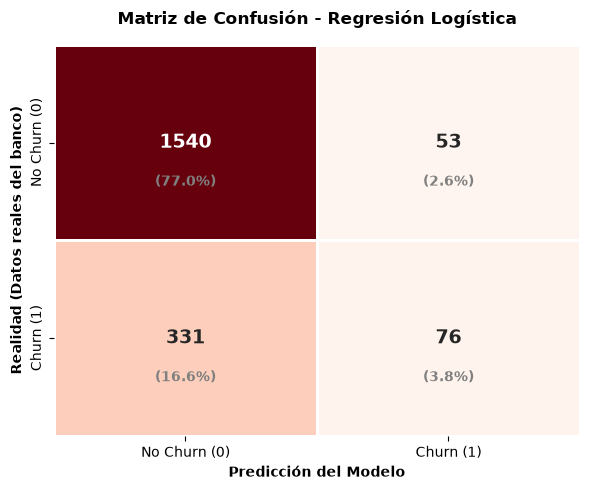

In [27]:
#Matriz de confusión
CM = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(CM, annot=True, fmt="d", cmap='Reds', cbar=False, linewidths=1, annot_kws={"size": 14, "weight": "bold"})

plt.title('Matriz de Confusión - Regresión Logística', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Realidad (Datos reales del banco)', fontsize=10, fontweight='bold')
plt.xlabel('Predicción del Modelo', fontsize=10, fontweight='bold')
plt.xticks([0.5, 1.5], ['No Churn (0)', 'Churn (1)'])
plt.yticks([0.5, 1.5], ['No Churn (0)', 'Churn (1)'], va='center')

total = CM.sum()
for i in range(2):
    for j in range(2):
        percentage = CM[i, j] / total * 100
        plt.text(j+0.5, i+0.7, f'({percentage:.1f}%)', 
                ha='center', va='center', fontsize=10, color='gray',fontweight='semibold')


plt.tight_layout()
plt.show()

Aciertos del modelo
True Negative = 77% de los datos corresponde correctamente a valores no churn, el modelo los logró identificar
True Positive = 3.8% de los clientes que desertaron fueron identificados exitosamente por el modelo
False Positive = El 2.6% de los clientes identificados como churn, no lo fueron. Esto impacta en el costo de inversión que el banco destine para campañas de retención
False Negative = El 16.6% de los clientes (331 clientes) fueron clasificados como "No Churn", al final desertaron el banco. Este tiene un impacto de pérdida de 30,156,926.74 Euros en capacidad de fondeo anual. Este es el valor que más afecta al banco

In [28]:
#Métricas
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

              precision    recall  f1-score   support

    No Churn       0.82      0.97      0.89      1593
       Churn       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



Conclusiones y consideraciones
1. El accuracy del modelo es del 81%, es decir que de todos los datos de test acertó el 81% (1616 de 2000) en sus predicciones. sin embargo, la medida no es totalmente confiable ya que está inflada por el desbalanceo de clases
2. El recall es bajo, del 19% (recall<60%) lo que en terminos prácticos significa que de cada 100 clientes que se van, el modelo sólo identifica 19, dice que 81 se quedan aunque estos también terminan desertando el banco, y sería una pérdida de capacidad de fondeo de aprox. de 7.4 millones de Euros al año
3. La precisión es aceptable del 59%, quiere decir, que para el mismo ejemplo de 100 clientes que el modelo dice que se van, realmente sólo acierta en 59 y clientes y 41 se quedan. La perdida en este caso sería en la inversión que realicen sobre estos clientes para "retenerlos", aunque no planeaban irse.
4. Al evaluar los promedios finales, el promedio por volumen (weighted avg = 81%) refleja una falsa sensación de éxito impulsada por el gran peso de la clase mayoritaria de clientes leales . Por el contrario, el promedio plano (macro avg = 58%) revela la verdadera deficiencia del algoritmo para resolver el problema de forma equitativa, confirmando que la Regresión Logística bajo un umbral del 50% no es óptima para mitigar la deserción, por lo tanto se sugiere la disminución de este umbral para mejorar el rendimiento del modelo.




AUC Score: 0.7748
El Umbral (Threshold) óptimo sugerido por la Curva ROC (Train) es: 0.2153


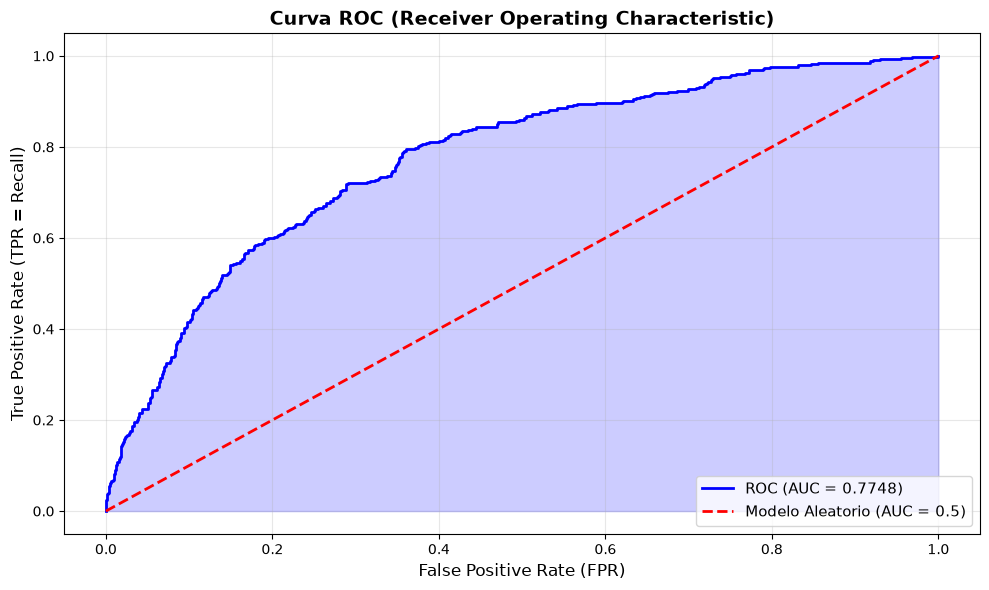

In [29]:
#Curva ROC - AUC

# Calculo de ROC y AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

print(f"AUC Score: {auc_score:.4f}")

#Threshold óptimo con el índice de Youden sobre Entrenamiento (Train)
#El índice de Youden busca la distancia vertical máxima entre el Recall (Eje Y de una curva ROC) 
# y la Tasa de Falsos Positivos (Eje X de una curva ROC)
y_pred_proba_train = LR_model.predict_proba(x_train_scaled)[:, 1]
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_pred_proba_train)

indice_optimo_train = np.argmax(tpr_train - fpr_train)
umbral_optimo = thresholds_train[indice_optimo_train]

print(f'El Umbral (Threshold) óptimo sugerido por la Curva ROC (Train) es: {umbral_optimo:.4f}')


#curva ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='blue', linewidth=2, label=f'ROC (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=2, label='Modelo Aleatorio (AUC = 0.5)')
plt.fill_between(fpr, tpr, alpha=0.2, color='blue') # Sombreado azul claro debajo de la curva

plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR = Recall)', fontsize=12)
plt.title('Curva ROC (Receiver Operating Characteristic)', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#Criterio para AUC
#AUC < 0.6: Modelo pobre, apenas mejor que azar
#AUC 0.6-0.7: Modelo aceptable, hay margen de mejora
#AUC 0.7-0.8: Buen modelo, rendimiento sólido
#AUC 0.8-0.9: Muy buen modelo, excelente capacidad discriminativa
#AUC > 0.9: Modelo excepcional



1. El AUC Score obtenido es de 0.77, lo que clasifica a la Regresión Logística como un buen modelo con rendimiento sólido. Esto significa que el algoritmo tiene un 77% de probabilidad de asignarle un porcentaje de riesgo más alto a un cliente que verdaderamente está en proceso de abandono (Churn) en comparación con un cliente que se va a quedar.
2. Para maximizar la rentabilidad del proyecto, se sugiere reconfigurar el modelo utilizando un umbral de decisión (Threshold) de 0.2153. Este número, calculado matemáticamente a través del Índice de Youden, representa el punto óptimo donde se comete la menor cantidad de errores de clasificación global. Al implementar este umbral del 21.53%, el banco incrementará drásticamente la captura de desertores (Recall). El banco deberá evaluar si el capital financiero salvado al retener a estos clientes de posible churn es mayor al costo de ofrecer beneficios y campañas de fidelización a los clientes que fueron etiquetados con una falsa alarma de que iban a abandonar, pero se quedaron(Falsos Positivos).

Exportar datos para Avance 2

In [30]:
#Creamos la ruta de destino (y la carpeta si no existe)
output_dir = '../data/processed/'
os.makedirs(output_dir, exist_ok=True)

y_train_export = pd.DataFrame(y_train, columns=['Exited'], index=y_train.index)
y_test_export = pd.DataFrame(y_test, columns=['Exited'], index=y_test.index)

# index=True para mantener el ID original de los clientes
#Dataframes escalados
x_train_scaled.to_csv(os.path.join(output_dir,'X_train_final_escalado.csv'), index=True)
x_test_scaled.to_csv(os.path.join(output_dir,'X_test_final_escalado.csv'), index=True)
#DataFrame de y 'Exited'
y_train_export.to_csv(os.path.join(output_dir, 'y_train_final.csv'), index=True)
y_test_export.to_csv(os.path.join(output_dir, 'y_test_final.csv'), index=True)
#Para el avance 3, no están escalados
x.to_csv(os.path.join(output_dir,'X_No escalado.csv'), index=True)
y.to_csv(os.path.join(output_dir,'y.csv'), index=True)

print('Los dataframe de entrenamiento y prueba fueron guardados en tu carpeta actual, por favor mover a la carpeta "Data"')

Los dataframe de entrenamiento y prueba fueron guardados en tu carpeta actual, por favor mover a la carpeta "Data"


In [31]:
#Ajuste de umbral de decisión
umbral_youden = 0.2153

# Recalculamos las predicciones usando la máscara lógica (SIN REENTRENAR)
y_pred_youden = (y_pred_proba>= umbral_youden).astype(int)

print('REPORTE OPTIMIZADO CON UMBRAL DEL 21.53% (ÍNDICE DE YOUDEN):')
print(classification_report(y_test, y_pred_youden, target_names=['No Churn', 'Churn']))

print('=' * 65)
print('REPORTE ORIGINAL CON UMBRAL DEL 50%')
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

REPORTE OPTIMIZADO CON UMBRAL DEL 21.53% (ÍNDICE DE YOUDEN):
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1593
       Churn       0.39      0.68      0.50       407

    accuracy                           0.72      2000
   macro avg       0.65      0.70      0.65      2000
weighted avg       0.80      0.72      0.74      2000

REPORTE ORIGINAL CON UMBRAL DEL 50%
              precision    recall  f1-score   support

    No Churn       0.82      0.97      0.89      1593
       Churn       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



Conclusiones
1. Al implementar el umbral óptimo del 21.53% sugerido por el Índice de Youden(en los datos de entrenamiento), el Recall para la clase Churn se incrementó drásticamente del 19% al 68%. En términos de negocio, el modelo pasa de ignorar al 81% de los desertores a capturar con éxito al 68% de los clientes en riesgo real de fuga, permitiendo la aplicación de campañas de retención proactivas sobre la gran masa de capitales en riesgo.
2. Como consecuencia del aumento en el recall, se redujo la precisión del Churn a un 39%, incrementando las falsas alarmas sobre los clientes estables (No Churn). Como efecto consecuente, este comportamiento arrastró el Accuracy global del 81% al 72% y el promedio ponderado (Weighted Avg del F1-Score) de 0.77 a 0.74.
3. A pesar de la caída provocada por el volumen en el promedio ponderado, el macro avg del F1-Score aumentó de 0.59 a 0.65. Al evaluar ambas clases con la misma relevancia analítica, este incremento certifica matemáticamente que el modelo optimizado posee una salud estructural superior y un comportamiento mucho más equitativo para resolver el problema real del desbalanceo.
4. El modelo del 21.53% es mejor que el base. Aunque el modelo base parecía correcto, dejaba escapar millones de forma silenciosa (30,156,926.74 Euros estimados). El optimizado gasta un poco más en marketing, pero salva el 68% de los fondos en riesgo. Si ponemos el mismo ejemplo de los 100 clientes que se van, el modelo capturaría 68 de ellos con éxito y dejaría ir 32, eso traduciría en una posible retención de 6,195,380.72 Euros anuales.